# GCSI Infrastructure Watchlist

## A custom news feed for named refineries, pipelines and storage sites

Every GCSI headline records the entities that linked it to a commodity (`matched_entities`) and their types
(`matched_entity_types`). Physical assets have their own types, such as `PHYSICAL_ASSET.PROCESSING_FACILITY` for
refineries and `PHYSICAL_ASSET.TRANSPORT_INFRASTRUCTURE` for pipelines, and the feed can be filtered to them with
`matched_entity_type_preset`. This notebook pulls those headlines and keeps the ones about a watchlist of named
oil assets that you choose.

### What this notebook shows

1. A **map** of the watchlist: where the news is, and how it reads for the commodity
2. A **timeline** of when each asset was in the news
3. The **headline feed** behind it, newest first

The watchlist and its coordinates are part of this example, not API data: edit them to follow your own assets.

> **Disclaimer:** This notebook is provided for informational and research purposes only. Nothing here constitutes financial advice or a recommendation to buy, sell, or hold any asset. Sentiment scores are model outputs describing how news was judged at publication; they are not price forecasts.

In [ ]:
%pip install requests pandas numpy matplotlib seaborn plotly kaleido

## Step 1: Configuration

Watchlist keys must match a `matched_entities` value exactly. Pipelines are placed at a main terminal or hub.

The API client, storage, metrics and chart helpers live in [`../utils`](../utils/), shared by every notebook in this folder. Open them to see how each step works.

In [2]:
import os
import sys
from datetime import datetime, timedelta, timezone
from pathlib import Path

sys.path.insert(0, str(Path('..').resolve()))  # notebooks/, for the shared utils package
from utils import charts, metrics
from utils.api import HORIZONS, LIST_SEPARATOR, GcsiClient, to_feed_frame

TICKER = 'BZ_COM'              # headlines linked to Brent Crude; a sector preset such as 'ENERGY' is wider but slower
LOOKBACK_DAYS = 14             # the historical feed covers at most 90 days
ENTITY_TYPE_PRESETS = [
    'PHYSICAL_ASSET.PROCESSING_FACILITY',
    'PHYSICAL_ASSET.TRANSPORT_INFRASTRUCTURE',
    'PHYSICAL_ASSET.STORAGE_FACILITY',
    'PHYSICAL_ASSET.PORT_TERMINAL',
]

# Entity name as the API returns it: (label, kind, latitude, longitude). Coordinates are approximate.
WATCHLIST = {
    'Ras Tanura Refinery': ('Ras Tanura', 'Refinery', 26.64, 50.16),
    'Riyadh Refinery': ('Riyadh', 'Refinery', 24.55, 46.85),
    'Rabigh Refinery': ('Rabigh', 'Refinery', 22.75, 39.00),
    'Moscow Refinery': ('Moscow', 'Refinery', 55.64, 37.80),
    'Ryazan Refinery': ('Ryazan', 'Refinery', 54.58, 39.80),
    'Kirishi Refinery': ('Kirishi', 'Refinery', 59.45, 32.02),
    'Saratov Refinery': ('Saratov', 'Refinery', 51.49, 46.07),
    'Afipsky Refinery': ('Afipsky', 'Refinery', 44.90, 38.84),
    'Beaumont Refinery': ('Beaumont', 'Refinery', 30.07, -94.07),
    'Houston Refinery': ('Houston', 'Refinery', 29.71, -95.24),
    'Druzhba Oil Pipeline': ('Druzhba', 'Pipeline', 52.85, 32.68),
    'Baku-Tbilisi-Ceyhan Pipeline': ('Baku-Tbilisi-Ceyhan', 'Pipeline', 36.88, 35.93),
    'East-West Crude Oil Pipeline': ('East-West (Saudi)', 'Pipeline', 24.09, 38.06),
    'Kirkuk-Baniyas Oil Pipelines': ('Kirkuk-Baniyas', 'Pipeline', 35.47, 44.39),
    'Uzen-Atyrau-Samara Pipeline': ('Uzen-Atyrau-Samara', 'Pipeline', 47.11, 51.92),
    'Cushing Oklahoma Storage': ('Cushing', 'Storage', 35.98, -96.77),
    'Jurong Rock Caverns': ('Jurong Rock Caverns', 'Storage', 1.25, 103.68),
}
NEUTRAL_BAND = 0.1             # timeline dots within ±0.1 are drawn grey

# Publisher text is shown when you run the notebook. The saved outputs in this repository were run with
# SHOW_HEADLINE_TEXT=0, so their tables leave out the headline and publisher.
SHOW_HEADLINE_TEXT = os.environ.get('SHOW_HEADLINE_TEXT', '1') == '1'
PLOTLY_RENDERER = 'png'        # a static map that also shows on GitHub; 'notebook' gives an interactive one

client = GcsiClient()          # API_KEY from the environment or a .env file, otherwise a prompt

## Step 2: Fetch the asset headlines

One paginated pull per entity-type preset. A headline that names several assets, or sits in several topics,
comes back once per topic, so the watchlist rows are reduced to one per article and asset: the most likely topic
is kept, and the scores are averaged across topics.

In [3]:
start = datetime.now(timezone.utc) - timedelta(days=LOOKBACK_DAYS)
raw = to_feed_frame([row for preset in ENTITY_TYPE_PRESETS
                     for row in client.feed_history(TICKER, start, entity_type_preset=preset)])
print(f'{len(raw):,} rows | {raw["link"].nunique():,} articles name a physical asset')

hits = metrics.watchlist_hits(raw, WATCHLIST)
print(f'{len(hits):,} article-asset pairs for {hits["asset"].nunique()} of {len(WATCHLIST)} watchlist assets')

6,492 rows | 4,673 articles name a physical asset
628 article-asset pairs for 17 of 17 watchlist assets


## Step 3: Map

Marker size is the number of articles in the window, and colour is their average short-term score
(green: bullish for the commodity, red: bearish). Grey markers had no articles in the window.

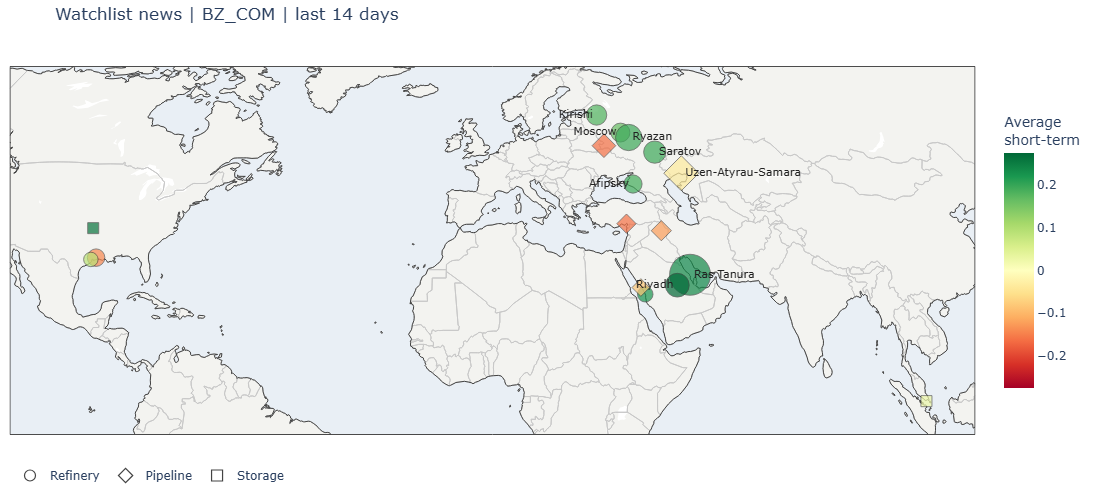

In [4]:
sites = metrics.watchlist_sites(hits, WATCHLIST)
charts.asset_map(sites, f'Watchlist news | {TICKER} | last {LOOKBACK_DAYS} days', renderer=PLOTLY_RENDERER)

## Step 4: Timeline

One row per asset, busiest at the top, with a dot for each article at the time Permutable processed it.

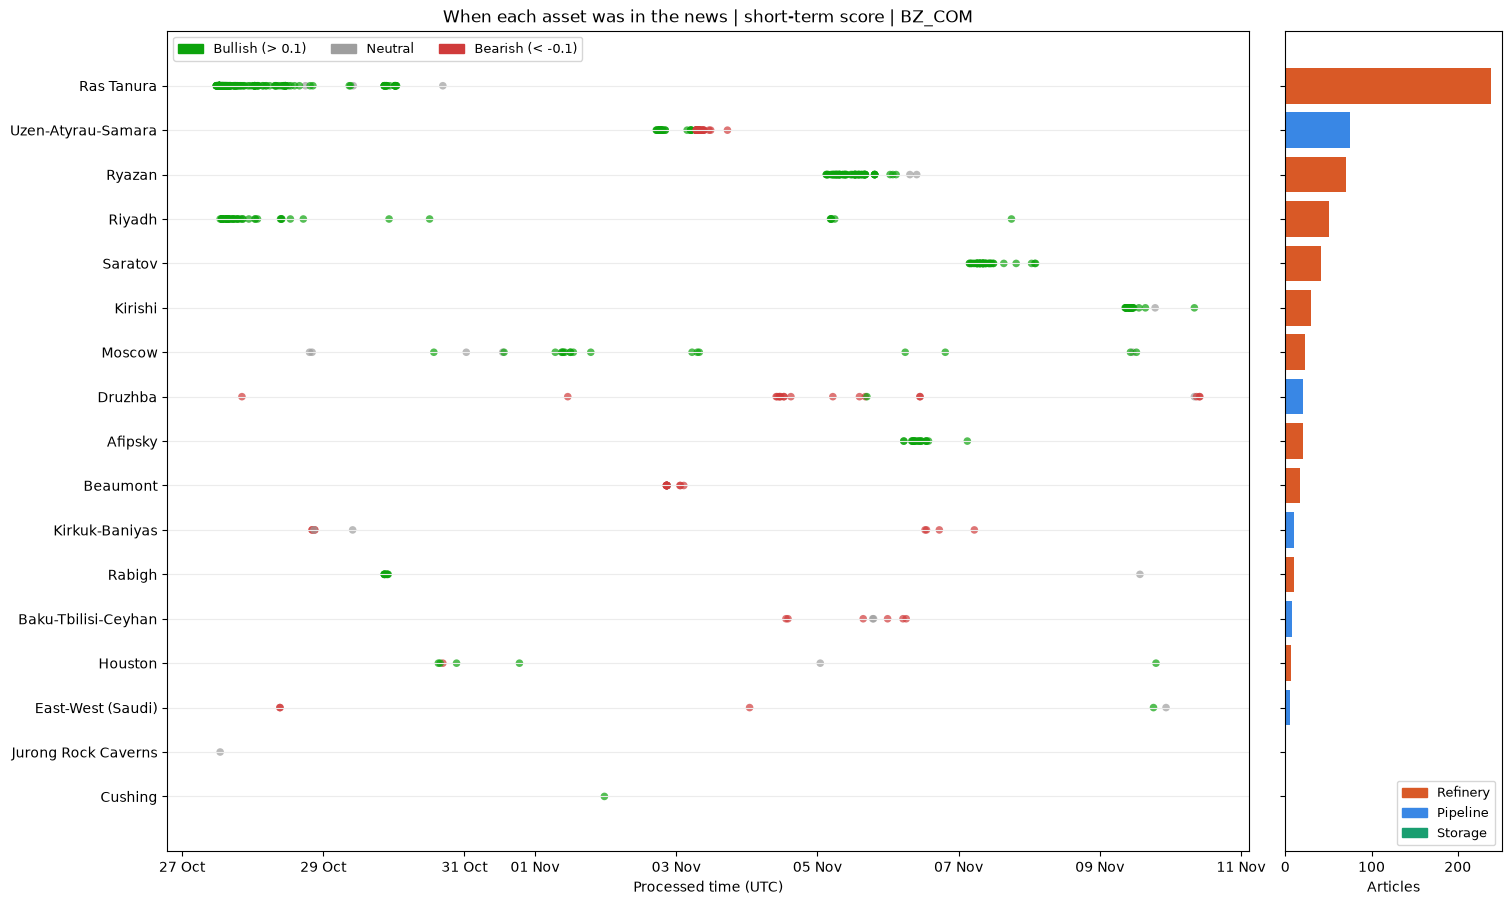

In [5]:
charts.asset_timeline(hits, f'When each asset was in the news | short-term score | {TICKER}', NEUTRAL_BAND)

## Step 5: Headline feed

The newest watchlist articles. Headline text belongs to its publisher: use it under your licence, and do not
republish it.

In [6]:
columns = ['processed_at', 'label', 'kind', 'country', 'topic', *HORIZONS, 'headline', 'source_name']
if not SHOW_HEADLINE_TEXT:
    columns = [c for c in columns if c not in ('headline', 'source_name')]
latest = hits.sort_values('processed_at', ascending=False)[columns].head(25)
latest['processed_at'] = latest['processed_at'].dt.strftime('%Y-%m-%d %H:%M')
latest['country'] = latest['country'].str.replace(LIST_SEPARATOR, ' / ', regex=False)
latest[HORIZONS] = latest[HORIZONS].round(3)
display(latest.rename(columns={'label': 'asset', **{h: h.replace('_sentiment_score', '') for h in HORIZONS}})
        .reset_index(drop=True))

,processed_at,asset,kind,country,topic,short_term,medium_term,long_term
0,2026-11-10 10:02,Druzhba,Pipeline,Kazakhstan,Energy::Supply::Infrastructure & Logistics,-0.221,-0.194,-0.112
1,2026-11-10 09:50,Druzhba,Pipeline,Kazakhstan,Energy::Supply::Infrastructure & Logistics,-0.226,-0.198,-0.126
2,2026-11-10 08:53,Druzhba,Pipeline,Kazakhstan,Energy::Supply::Infrastructure & Logistics,-0.226,-0.194,-0.140
3,2026-11-10 08:10,Kirishi,Refinery,Russian Federation / Ukraine,Energy::Macro::Conflict,0.244,0.196,0.014
4,2026-11-10 08:10,Druzhba,Pipeline,Kazakhstan / Russian Federation,Energy::Supply::Infrastructure & Logistics,-0.062,-0.057,-0.017
5,2026-11-09 22:32,East-West (Saudi),Pipeline,Saudi Arabia,Energy::Macro::Conflict,0.053,0.058,0.025
6,2026-11-09 19:07,Houston,Refinery,United States,Energy::Supply::Refining,0.150,0.131,0.069
7,2026-11-09 18:50,Kirishi,Refinery,Russian Federation,Energy::Supply::Disruptions,-0.057,-0.053,-0.004
8,2026-11-09 18:16,East-West (Saudi),Pipeline,Israel / Saudi Arabia,Energy::Supply::Disruptions,0.162,0.098,0.008
9,2026-11-09 15:31,Kirishi,Refinery,Russian Federation / Ukraine,Energy::Macro::Conflict,0.158,0.122,0.009


## Next steps

- **Your own assets:** add entries to `WATCHLIST`. To find the exact names, look at `raw['matched_entities']`
  from Step 2, or list the entity types with `GET /v1/headlines/topics/gcsi/entity_types/presets`.
- **Wider coverage:** set `TICKER` to a sector preset such as `'ENERGY'`. Each headline then comes back once per
  linked commodity, so the pull is larger and slower.
- **Longer history:** raise `LOOKBACK_DAYS` up to 90.
- **Live updates:** `notebooks/live/gcsi_headline_polling.ipynb` shows how to poll the live feed into SQLite.